In [2]:
from huggingface_hub import HfApi, hf_hub_download
import json

repo = "dronefreak/BDD100K"
entries = HfApi().list_repo_tree(
    repo, repo_type="dataset",
    path_in_repo="data/labels/100k/train",
    recursive=True,
)
label_path = next(item.path for item in entries if item.path.endswith(".json"))

local_file = hf_hub_download(repo, label_path, repo_type="dataset")
with open(local_file) as f:
    annotation = json.load(f)

record = annotation[0] if isinstance(annotation, list) else annotation
print("Training file:", label_path)
print("Annotation fields:", list(record))

0000f77c-6257be58.json:   0%|          | 0.00/7.90k [00:00<?, ?B/s]

Training file: data/labels/100k/train/shard_000/0000f77c-6257be58.json
Annotation fields: ['name', 'frames', 'attributes']


In [3]:
frame = record["frames"][0]
objects = frame["objects"]

print("Image name:", record["name"])
print("Object categories:", sorted({obj["category"] for obj in objects}))

boxed = next((obj for obj in objects if "box2d" in obj), None)
if boxed:
    print("Example labeled box:", boxed["category"], boxed["box2d"])

Image name: 0000f77c-6257be58
Object categories: ['area/drivable', 'car', 'lane/road curb', 'traffic light', 'traffic sign']
Example labeled box: traffic light {'x1': 1125.902264, 'y1': 133.184488, 'x2': 1156.978645, 'y2': 210.875445}


data/images_100k/100k/train/shard_000/00(…): reconstructing file:   0%|          |  0.00B / 74.6kB            

data/images_100k/100k/train/shard_000/00(…): downloading bytes:           |  0.00B            

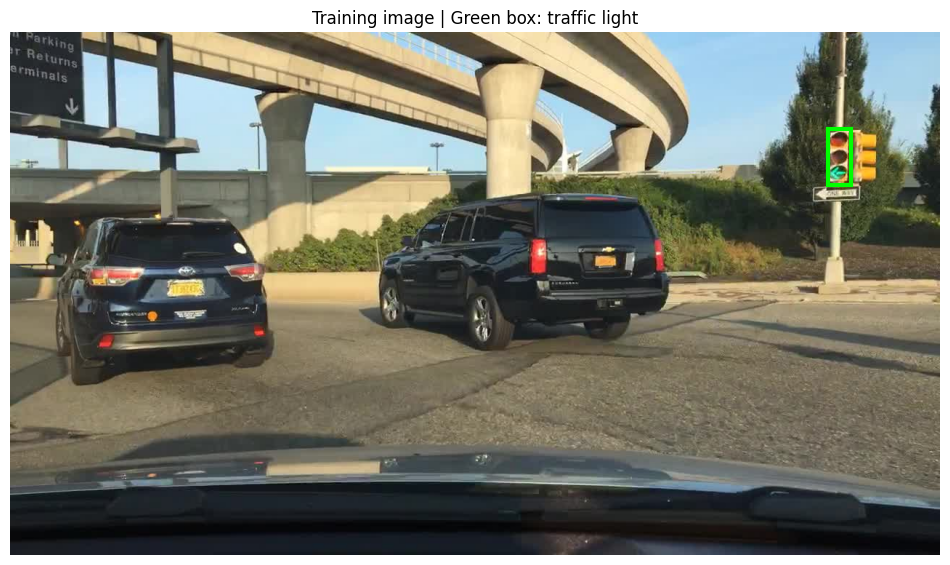

In [4]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Find the road photo with the same name as your annotation.
image_id = Path(record["name"]).stem
files = HfApi().list_repo_tree(
    repo, repo_type="dataset", path_in_repo="data/images_100k", recursive=True
)
image_path = next(
    item.path for item in files
    if Path(item.path).name.lower() == f"{image_id}.jpg"
)

photo = Image.open(hf_hub_download(repo, image_path, repo_type="dataset"))
box = boxed["box2d"]

fig, ax = plt.subplots(figsize=(12, 7))
ax.imshow(photo)
ax.add_patch(Rectangle(
    (box["x1"], box["y1"]),
    box["x2"] - box["x1"], box["y2"] - box["y1"],
    fill=False, edgecolor="lime", linewidth=3
))
ax.set_title(f'Training image | Green box: {boxed["category"]}')
ax.axis("off")
plt.show()

0000f77c-62c2a288.json:   0%|          | 0.00/16.8k [00:00<?, ?B/s]

0000f77c-cb820c98.json:   0%|          | 0.00/8.54k [00:00<?, ?B/s]

0001542f-5ce3cf52.json:   0%|          | 0.00/12.0k [00:00<?, ?B/s]

0001542f-7c670be8.json:   0%|          | 0.00/8.60k [00:00<?, ?B/s]

0001542f-ec815219.json:   0%|          | 0.00/13.2k [00:00<?, ?B/s]

0004974f-05e1c285.json:   0%|          | 0.00/12.1k [00:00<?, ?B/s]

... (41 outputs left out)

data/images_100k/100k/train/shard_000/00(…): reconstructing file:   0%|          |  0.00B / 44.3kB            

data/images_100k/100k/train/shard_000/00(…): downloading bytes:           |  0.00B            

data/images_100k/100k/train/shard_000/00(…): reconstructing file:   0%|          |  0.00B / 58.8kB            

data/images_100k/100k/train/shard_000/00(…): downloading bytes:           |  0.00B            

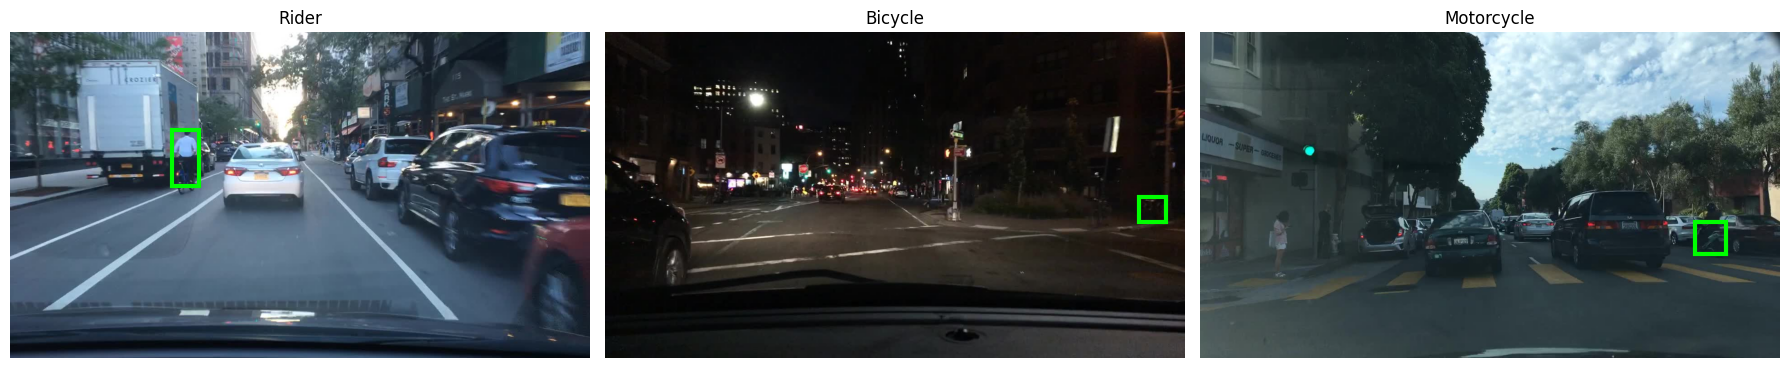

In [5]:
# The raw annotations may call bicycles "bike" and motorcycles "motor".
class_names = {
    "rider": "rider",
    "bike": "bicycle", "bicycle": "bicycle",
    "motor": "motorcycle", "motorcycle": "motorcycle",
}
examples = {}

label_files = HfApi().list_repo_tree(
    repo, repo_type="dataset",
    path_in_repo="data/labels/100k/train", recursive=True
)

for entry in label_files:
    if not entry.path.endswith(".json"):
        continue

    path = hf_hub_download(repo, entry.path, repo_type="dataset")
    with open(path) as f:
        data = json.load(f)
    sample = data[0] if isinstance(data, list) else data

    for obj in sample["frames"][0]["objects"]:
        label = class_names.get(obj["category"])
        box = obj.get("box2d")
        if label is None or label in examples or not box:
            continue
        if min(box["x2"] - box["x1"], box["y2"] - box["y1"]) < 40:
            continue  # Pick a box large enough to see clearly.

        image_name = Path(sample["name"]).stem + ".jpg"
        examples[label] = (image_name, box)
        print(f"Found {label}: {image_name}", flush=True)
        break

    if len(examples) == 3:
        break

assert len(examples) == 3, f"Classes found: {list(examples)}"

# Match the three filenames in the training image folder.
wanted = {name for name, box in examples.values()}
image_paths = {}
for entry in HfApi().list_repo_tree(
    repo, repo_type="dataset",
    path_in_repo="data/images_100k/100k/train", recursive=True
):
    name = Path(entry.path).name
    if name in wanted:
        image_paths[name] = entry.path
    if len(image_paths) == len(wanted):
        break

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, label in zip(axes, ["rider", "bicycle", "motorcycle"]):
    name, box = examples[label]
    photo_path = hf_hub_download(repo, image_paths[name], repo_type="dataset")
    ax.imshow(Image.open(photo_path))
    ax.add_patch(Rectangle(
        (box["x1"], box["y1"]),
        box["x2"] - box["x1"], box["y2"] - box["y1"],
        fill=False, edgecolor="lime", linewidth=3
    ))
    ax.set_title(label.capitalize())
    ax.axis("off")

plt.tight_layout()
plt.savefig("roadsight_training_examples.png", dpi=160, bbox_inches="tight")
plt.show()

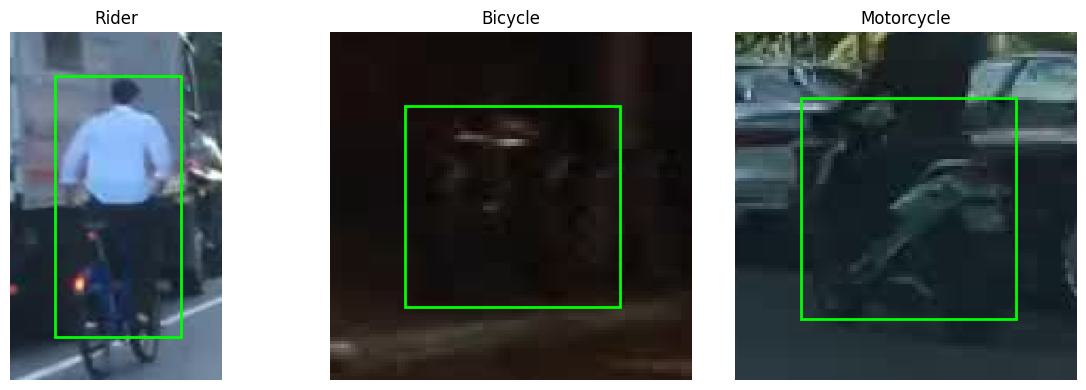

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, label in zip(axes, ["rider", "bicycle", "motorcycle"]):
    name, box = examples[label]
    path = hf_hub_download(repo, image_paths[name], repo_type="dataset",
                           local_files_only=True)
    image = Image.open(path).convert("RGB")

    x1, y1, x2, y2 = (box[k] for k in ("x1", "y1", "x2", "y2"))
    pad = 20
    left, top = max(0, int(x1) - pad), max(0, int(y1) - pad)
    right = min(image.width, int(x2) + pad + 1)
    bottom = min(image.height, int(y2) + pad + 1)

    ax.imshow(image.crop((left, top, right, bottom)))
    ax.add_patch(Rectangle((x1 - left, y1 - top), x2 - x1, y2 - y1,
                           fill=False, edgecolor="lime", linewidth=2))
    ax.set_title(label.capitalize())
    ax.axis("off")

plt.tight_layout()
plt.show()